# [예시] 데이터 프로젝트 노트북 — 교육·상담 진로 (students.csv)

이 노트북은 **어떻게 푸는지 보여 주는 완성본**입니다. 우리 팀은 `project_template.ipynb`를 열어 우리 진로와 데이터로 직접 채워 보세요.

- **진로 키워드**: 교육·상담 (교사, 상담교사, 교육 정책 연구원, 사회복지사)
- **탐구 질문(필수)**: 공부 시간 구간(studytime)별로 최종 성적(G3)의 평균은 어떻게 다를까?
- **예상**: 공부 시간이 길수록 평균 성적이 높을 것이다.

In [1]:
# 미션 0. 불러오기
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/daradarav86/bigdata/main/data/students.csv"
df = pd.read_csv(url)
display(df.head())

  school   age address  studytime  traveltime  ... health absences    G1  G2    G3
0     GP  18.0       U          2           2  ...      3      4.0   0.0  11  11.0
1     GP  17.0       U          2           1  ...      3      2.0   9.0  11  11.0
2     GP  15.0       U          2           1  ...      3      6.0  12.0  13  12.0
3     GP  15.0       U          3           1  ...      5      0.0  14.0  14  14.0
4     GP  16.0       U          2           1  ...      5      0.0  11.0  13  13.0

[5 rows x 15 columns]


## 미션 1. 데이터 구조 확인
- 한 행: 포르투갈 학생 1명의 기록 1건 / 649행 × 15열
- 쓸 열: `studytime`(공부 시간 구간 1~4, int64), `G3`(마지막 학기 성적, float64), `higher`(진학 희망, object)
- `info()`를 보면 G3는 642개만 값이 있어요 → 빈칸이 7개

In [1]:
print(df.shape)       # (행 수, 열 수)
print(df.columns)     # 열 이름 (복사해서 쓰면 오타가 없어요)
df.info()             # 자료형과 비어 있지 않은 값의 개수

(649, 15)
Index(['school', 'age', 'address', 'studytime', 'traveltime', 'schoolsup',
       'activities', 'internet', 'higher', 'freetime', 'health', 'absences',
       'G1', 'G2', 'G3'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    object
 1   age         646 non-null    float64
 2   address     649 non-null    object
 3   studytime   649 non-null    int64
 4   traveltime  649 non-null    int64
 5   schoolsup   649 non-null    object
 6   activities  649 non-null    object
 7   internet    649 non-null    object
 8   higher      649 non-null    object
 9   freetime    649 non-null    int64
 10  health      649 non-null    int64
 11  absences    645 non-null    float64
 12  G1          644 non-null    float64
 13  G2          649 non-null    int64
 14  G3          642 non-null    float64
dtypes: 

## 미션 2. 빈칸(결측치) 확인과 처리
G3 열의 빈칸은 7개(약 1%)입니다. `dropna()`를 쓰면 649행 → 630행으로 19행이 줄어듭니다.
→ **그대로 두기**로 했습니다. groupby 평균은 빈칸을 자동으로 건너뛰기 때문이에요.

In [1]:
print(df.isnull().sum())      # 열별 빈칸 개수

df_removed = df.dropna()      # 빈칸이 있는 행을 모두 제거한 표 (원본 df는 그대로)
print("원본", df.shape, "→ 제거 후", df_removed.shape)

df_use = df.copy()    # ← 분석에 쓸 표: df.copy()(그대로) / df_removed(제거) 중 선택
# 선택한 방법과 이유: 그대로 두기 — G3 빈칸이 7개(약 1%)뿐이고 groupby 평균이 빈칸을 건너뛴다.

school        0
age           3
address       0
studytime     0
traveltime    0
schoolsup     0
activities    0
internet      0
higher        0
freetime      0
health        0
absences      4
G1            5
G2            0
G3            7
dtype: int64
원본 (649, 15) → 제거 후 (630, 15)


## 미션 3. 그룹별 분석
**우리 질문:** 공부 시간 구간별로 최종 성적의 평균은 어떻게 다를까?

In [1]:
result = df_use.groupby("studytime")["G3"].mean()    # 묶는 기준 → 계산할 열 → 통계
display(result)

studytime
1    10.866667
2    12.105611
3    13.361702
4    13.057143
Name: G3, dtype: float64


## 미션 4. 그래프

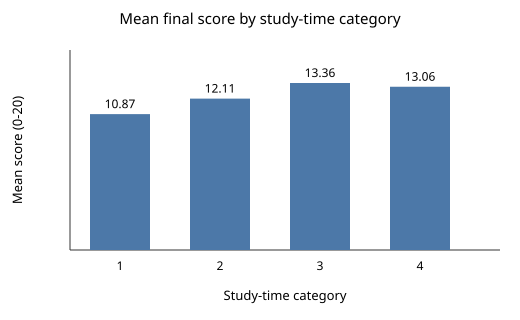

In [1]:
result.plot(kind="bar")
plt.title("Mean final score by study-time category")
plt.xlabel("Study-time category")
plt.ylabel("Mean score (0-20)")
plt.show()

## 결과 읽기와 해석

In [1]:
print("가장 큰 그룹:", result.idxmax(), round(result.max(), 2))
print("가장 작은 그룹:", result.idxmin(), round(result.min(), 2))
print("차이:", round(result.max() - result.min(), 2))

가장 큰 그룹: 3 13.36
가장 작은 그룹: 1 10.87
차이: 2.5


### 해석
① **사실**: 공부 시간 구간별 최종 성적 평균은 구간 3(5~10시간)이 13.36점으로 가장 높고, 구간 1(2시간 미만)이 10.87점으로 가장 낮았다.
② **비교**: 두 집단의 차이는 2.49점으로, 구간 3의 평균이 약 1.23배 높았다.
③ **의미**: 공부 시간이 길수록 성적이 높아지는 경향이 있지만, 가장 오래 공부하는 구간 4(13.06점)는 구간 3보다 조금 낮았다.

**한계**: 구간 4는 35명뿐이고, 평균만 비교했으며, 공부 시간이 성적의 원인이라고 단정할 수 없다.

**진로 연결**: 교사·상담교사가 학생에게 공부 시간 목표를 제안할 때 참고할 수 있다. 다만 ‘무조건 오래’가 아니라 5~10시간 구간의 성적이 가장 높았다는 점도 함께 이야기해야 한다.

## (선택) 두 번째 질문 — 진학 희망(higher)별 성적

In [1]:
result2 = df_use.groupby("higher")["G3"].mean()
display(result2)

higher
no      8.823529
yes    12.304878
Name: G3, dtype: float64


진학을 희망하는 학생(yes)의 평균은 12.30점, 희망하지 않는 학생(no)은 8.82점으로 3.48점 차이가 났다. 함께 움직이는 경향은 있지만 어느 쪽이 원인인지는 알 수 없다.